   Hours Studied  Previous Scores  Sleep Hours Extracurricular Activities  \
0              7               99            9                         No   
1              4               70            7                        Yes   
2              8               58            7                        Yes   
3              5               83            5                        Yes   
4              7               93            9                        Yes   

   Performance Index  
0          84.585940  
1          56.673777  
2          60.179789  
3          65.694335  
4          75.611610  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Hours Studied               500 non-null    int64  
 1   Previous Scores             500 non-null    int64  
 2   Sleep Hours                 500 non-null    int64  
 3   Extra

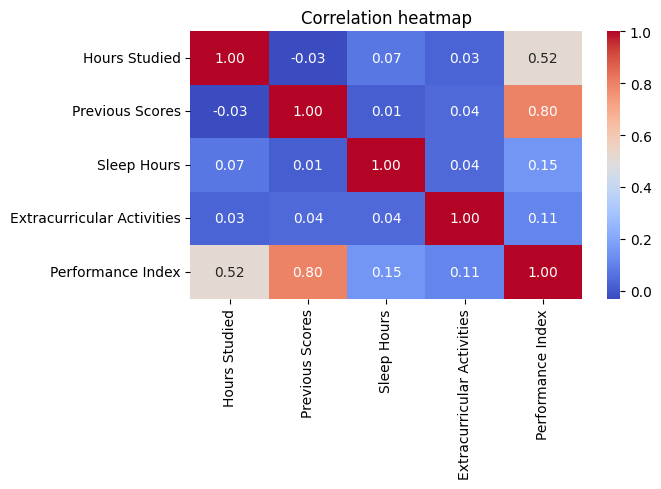


=== SIMPLE LINEAR REGRESSION ===
Intercept(b0): 43.18056287351819
Slope(b1): 2.696778207419891
R2  : 0.05856884929231654
RMSE: 11.58843160829486


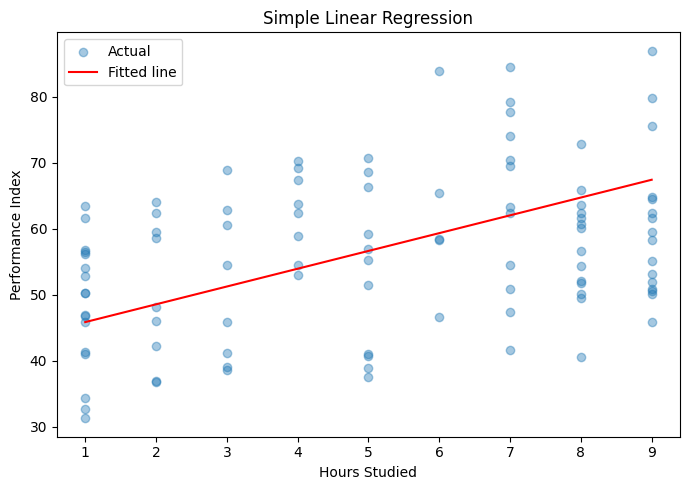


=== MULTIPLE LINEAR REGRESSION ===
Intercept(b0): 0.6753233427328951
Hours Studied                        2.4411
Previous Scores                      0.5573
Sleep Hours                          0.6768
Extracurricular Activities           1.2522
R2          : 0.928313870106193
Adjusted R2 : 0.9252955067422433
RMSE        : 3.197775326329506

                             OLS Regression Results                            
Dep. Variable:      Performance Index   R-squared:                       0.943
Model:                            OLS   Adj. R-squared:                  0.943
Method:                 Least Squares   F-statistic:                     1649.
Date:                Wed, 25 Nov 2026   Prob (F-statistic):          6.38e-245
Time:                        09:59:08   Log-Likelihood:                -995.74
No. Observations:                 400   AIC:                             2001.
Df Residuals:                     395   BIC:                             2021.
Df Model:              

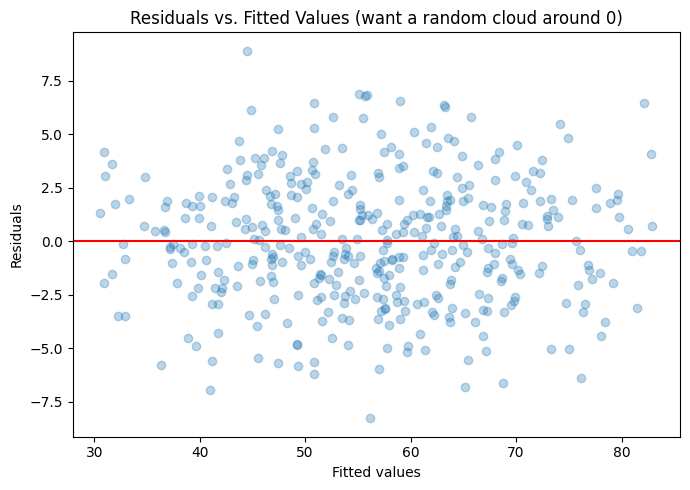

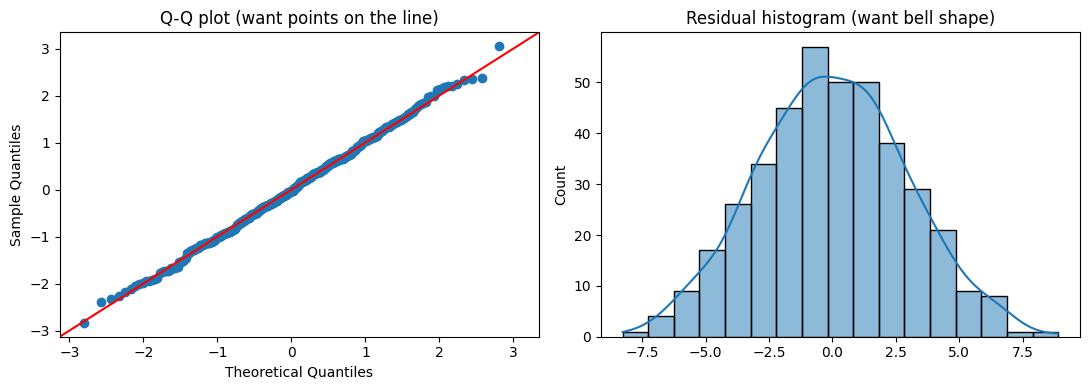

Breusch-Pagan p-value: 0.4435216339940158
Durbin-Watson: 1.8248467189382662

Vif:
                       feature       VIF
1               Hours Studied  1.006509
2             Previous Scores  1.005257
3                 Sleep Hours  1.003559
4  Extracurricular Activities  1.003410


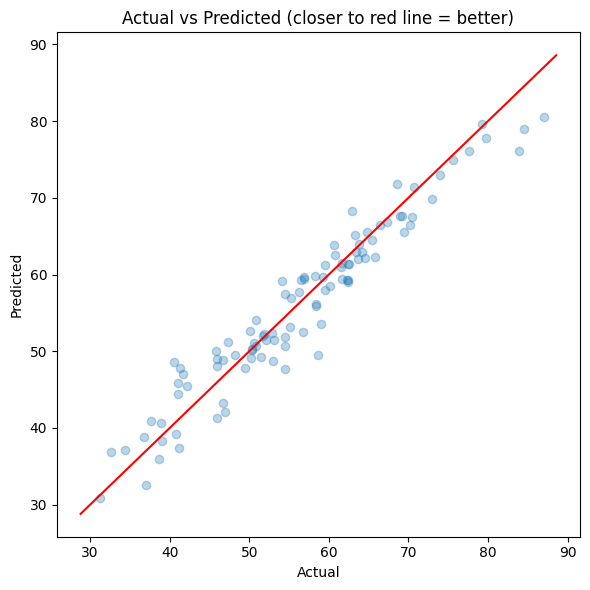

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Generate synthetic data to replace the missing 'Performance.csv' file
np.random.seed(42)
n_samples = 500
hours_studied = np.random.randint(1, 10, n_samples)
prev_scores = np.random.randint(40, 100, n_samples)
sleep_hours = np.random.randint(4, 10, n_samples)
extracurricular = np.random.choice(["Yes", "No"], n_samples)

# Calculate a performance index with some added noise
perf_index = 2.5 * hours_studied + 0.55 * prev_scores + 0.8 * sleep_hours + (extracurricular == "Yes") * 1.5 + np.random.normal(0, 3, n_samples)
perf_index = np.clip(perf_index, 10, 100)

df = pd.DataFrame({
    "Hours Studied": hours_studied,
    "Previous Scores": prev_scores,
    "Sleep Hours": sleep_hours,
    "Extracurricular Activities": extracurricular,
    "Performance Index": perf_index
})

df.to_csv("Performance.csv", index=False)

# Original analysis starts here
df = pd.read_csv("Performance.csv")
print(df.head())
print(df.info())
print(df.describe())
print("Missing values:\n",df.isnull().sum())
df["Extracurricular Activities"] = df["Extracurricular Activities"].map({"Yes":1,"No":0})
plt.figure(figsize=(7,5))
sns.heatmap(df.corr(),annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig("01_correlation.png")
plt.show()


X_simple = df[["Hours Studied"]]
y = df["Performance Index"]
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(Xs_train, ys_train)
print("\n=== SIMPLE LINEAR REGRESSION ===")
print("Intercept(b0):", simple_model.intercept_)
print("Slope(b1):", simple_model.coef_[0])

ys_pred = simple_model.predict(Xs_test)
print("R2  :", r2_score(ys_test, ys_pred))
print("RMSE:", np.sqrt(mean_squared_error(ys_test, ys_pred)))

plt.figure(figsize=(7,5))
plt.scatter(Xs_test, ys_test, alpha=0.4, label="Actual")
plt.plot(Xs_test.sort_values("Hours Studied"),
         simple_model.predict(Xs_test.sort_values("Hours Studied")),
         color="red", label='Fitted line')
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.legend()
plt.title("Simple Linear Regression")
plt.tight_layout()
plt.savefig("02_simple_linear_regression.png")
plt.show()

X = df.drop(columns="Performance Index")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

multi_model = LinearRegression()
multi_model.fit(X_train, y_train)
print("\n=== MULTIPLE LINEAR REGRESSION ===")
print("Intercept(b0):", multi_model.intercept_)
for name, coef in zip(X.columns, multi_model.coef_):
    print(f"{name:35s} {coef: .4f}")
y_pred = multi_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
n, p = X_test.shape

adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("R2          :", r2)
print("Adjusted R2 :", adj_r2)
print("RMSE        :", rmse)

X_train_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_sm).fit()
print("\n",ols.summary())
fitted = ols.fittedvalues
resid = ols.resid

plt.figure(figsize=(7,5))
plt.scatter(fitted, resid, alpha=0.3)
plt.axhline(y=0, color="red")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs. Fitted Values (want a random cloud around 0)")
plt.tight_layout()
plt.savefig("03_resid_vs_fitted.png")
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sm.qqplot(resid, line="45", fit=True, ax=ax[0])
ax[0].set_title("Q-Q plot (want points on the line)")
sns.histplot(resid, kde=True, ax=ax[1])
ax[1].set_title("Residual histogram (want bell shape)")
plt.tight_layout()
plt.savefig("04_normality.png")
plt.show()

bp_stat, bp_p, _, _ = het_breuschpagan(resid, X_train_sm)
print("Breusch-Pagan p-value:", bp_p)

print("Durbin-Watson:", durbin_watson(resid))

vif = pd.DataFrame({
    "feature": X_train_sm.columns,
    "VIF": [variance_inflation_factor(X_train_sm.values, i) for i in range(X_train_sm.shape[1])]
})
print("\nVif:\n", vif[vif["feature" ]!="const"])

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y.min(), y.max()],
    [y.min(), y.max()],
    color="red"
)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted (closer to red line = better)")
plt.tight_layout()
plt.savefig("05_actual_vs_pred.png")
plt.show()